In [3]:
import os
import pandas as pd
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from dotenv import load_dotenv

load_dotenv("../.env")
print("imports OK", os.getenv("DB_HOST"))

imports OK aws-0-ap-northeast-2.pooler.supabase.com


In [4]:
url = URL.create(
    "postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)
engine = create_engine(url, connect_args={"connect_timeout": 20})

loss = pd.read_sql("SELECT * FROM forest_loss", engine)
print(loss.shape)

(24, 5)


In [5]:
fires = pd.read_sql("SELECT * FROM fire_alerts", engine)
logs = pd.read_sql("SELECT * FROM validation_logs", engine)
print(fires.shape, logs.shape)

(11894, 15) (2, 6)


In [6]:
display(loss.head(10))
display(fires.head())
display(logs)

,id,region,country,year,area_ha
0,1,AUS,Australia,2001,218813.58
1,2,AUS,Australia,2002,312150.31
2,3,AUS,Australia,2003,373847.16
3,4,AUS,Australia,2004,124768.69
4,5,AUS,Australia,2005,177024.18
5,6,AUS,Australia,2006,186304.31
6,7,AUS,Australia,2007,372723.43
7,8,AUS,Australia,2008,205723.69
8,9,AUS,Australia,2009,203709.60
9,10,AUS,Australia,2010,290725.26


,id,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight
0,1,-15.74340,144.22115,309.83,0.43,0.38,2026-10-13,1539,N,VIIRS,n,2.0NRT,291.87,0.91,N
1,2,-15.73989,144.22179,302.30,0.43,0.38,2026-10-13,1539,N,VIIRS,n,2.0NRT,291.51,0.91,N
2,3,-15.73920,144.21774,310.94,0.43,0.38,2026-10-13,1539,N,VIIRS,n,2.0NRT,291.95,0.91,N
3,4,-15.73569,144.21835,312.97,0.43,0.38,2026-10-13,1539,N,VIIRS,n,2.0NRT,292.09,1.51,N
4,5,-15.73149,144.21494,317.71,0.43,0.38,2026-10-13,1539,N,VIIRS,n,2.0NRT,292.13,1.56,N


,id,source_file,records_processed,records_failed,status,created_at
0,1,firms_VIIRS_SNPP_NRT_20261017T154113Z.csv,11894,0,SUCCESS,2026-11-02 12:04:27.057519
1,2,gfw_gadm__tcl__iso_change_AUS_20261017T170351Z...,24,0,SUCCESS,2026-11-02 12:04:35.658508


In [7]:
print(loss.dtypes)
print(fires.dtypes)

id           int64
region         str
country        str
year         int64
area_ha    float64
dtype: object
id              int64
latitude      float64
longitude     float64
bright_ti4    float64
scan          float64
track         float64
acq_date       object
acq_time          str
satellite         str
instrument        str
confidence        str
version           str
bright_ti5    float64
frp           float64
daynight          str
dtype: object


In [8]:
print("=== forest_loss ===")
print(loss.isna().sum())
print("duplicates:", loss.duplicated(subset=["year"]).sum())

print("\n=== fire_alerts ===")
print(fires.isna().sum())
print("duplicates (lat, lon, date, time):",
      fires.duplicated(subset=["latitude", "longitude", "acq_date", "acq_time"]).sum())

=== forest_loss ===
id         0
region     0
country    0
year       0
area_ha    0
dtype: int64
duplicates: 0

=== fire_alerts ===
id            0
latitude      0
longitude     0
bright_ti4    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_ti5    0
frp           0
daynight      0
dtype: int64
duplicates (lat, lon, date, time): 0


In [9]:
fires["acq_date"] = pd.to_datetime(fires["acq_date"])
fires["acq_time"] = fires["acq_time"].astype(str).str.zfill(4)
fires["hour"] = fires["acq_time"].str[:2].astype(int)
fires["confidence"] = fires["confidence"].map({"l": "low", "n": "nominal", "h": "high"})

print("Date range:", fires["acq_date"].min(), "to", fires["acq_date"].max())
print(fires["confidence"].value_counts())
print(fires["daynight"].value_counts())

Date range: 2026-10-13 00:00:00 to 2026-10-17 00:00:00
confidence
nominal    10464
high         760
low          670
Name: count, dtype: int64
daynight
D    7067
N    4827
Name: count, dtype: int64


In [10]:
display(loss.describe())
display(fires[["bright_ti4", "bright_ti5", "frp", "scan", "track"]].describe())

,id,year,area_ha
count,24.000000,24.000000,2.400000e+01
mean,12.500000,2012.500000,3.840972e+05
std,7.071068,7.071068,5.172178e+05
min,1.000000,2001.000000,1.189864e+05
25%,6.750000,2006.750000,1.848957e+05
50%,12.500000,2012.500000,2.438156e+05
75%,18.250000,2018.250000,2.960815e+05
max,24.000000,2024.000000,2.356518e+06


,bright_ti4,bright_ti5,frp,scan,track
count,11894.000000,11894.000000,11894.000000,11894.000000,11894.000000
mean,332.945346,297.678060,10.728461,0.460890,0.479661
std,19.527533,10.086363,20.818912,0.089496,0.114955
min,208.000000,228.310000,0.000000,0.320000,0.360000
25%,314.410000,291.550000,2.230000,0.390000,0.380000
50%,336.610000,296.570000,5.270000,0.440000,0.440000
75%,346.700000,303.540000,10.310000,0.520000,0.560000
max,367.000000,384.710000,543.700000,0.790000,0.780000


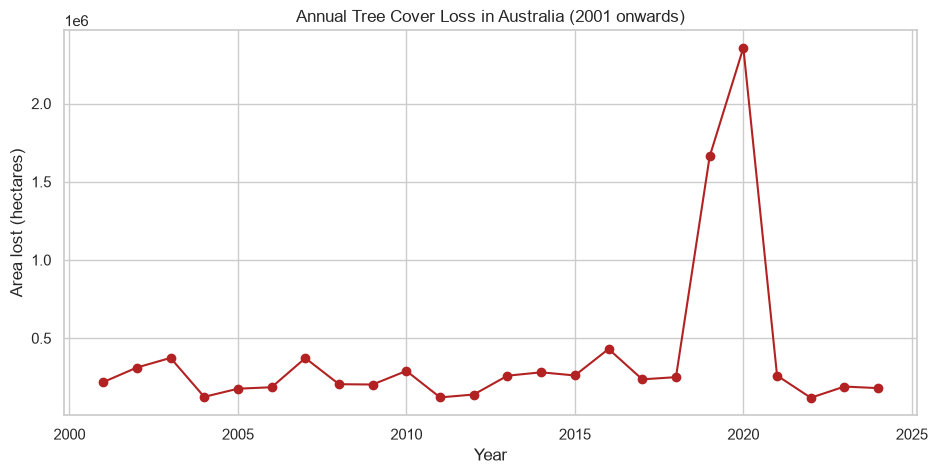

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

plt.figure(figsize=(11, 5))
plt.plot(loss["year"], loss["area_ha"], marker="o", color="firebrick")
plt.title("Annual Tree Cover Loss in Australia (2001 onwards)")
plt.xlabel("Year")
plt.ylabel("Area lost (hectares)")
plt.show()

In [12]:
loss = loss.sort_values("year")
loss["yoy_change_pct"] = loss["area_ha"].pct_change() * 100

print("Highest loss year:\n", loss.loc[loss["area_ha"].idxmax(), ["year", "area_ha"]])
print("\nLowest loss year:\n", loss.loc[loss["area_ha"].idxmin(), ["year", "area_ha"]])
print("\nAverage loss per year (ha):", round(loss["area_ha"].mean(), 2))
display(loss[["year", "area_ha", "yoy_change_pct"]].round(2))

Highest loss year:
 year          2020.00
area_ha    2356517.98
Name: 19, dtype: float64

Lowest loss year:
 year         2022.00
area_ha    118986.45
Name: 21, dtype: float64

Average loss per year (ha): 384097.19


,year,area_ha,yoy_change_pct
0,2001,218813.58,NaN
1,2002,312150.31,42.66
2,2003,373847.16,19.77
3,2004,124768.69,-66.63
4,2005,177024.18,41.88
5,2006,186304.31,5.24
6,2007,372723.43,100.06
7,2008,205723.69,-44.81
8,2009,203709.60,-0.98
9,2010,290725.26,42.72


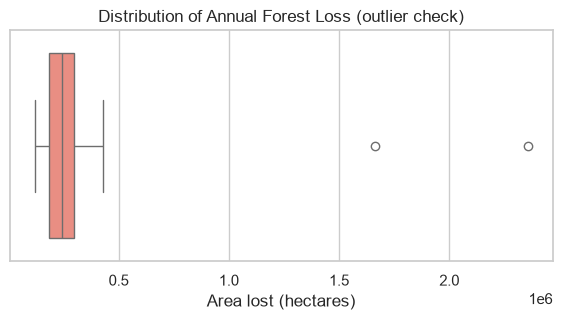

In [13]:
plt.figure(figsize=(7, 3))
sns.boxplot(x=loss["area_ha"], color="salmon")
plt.title("Distribution of Annual Forest Loss (outlier check)")
plt.xlabel("Area lost (hectares)")
plt.show()

In [14]:
fires_clean = fires.drop_duplicates(
    subset=["latitude", "longitude", "acq_date", "acq_time"]
).copy()
print(len(fires), "->", len(fires_clean))

11894 -> 11894


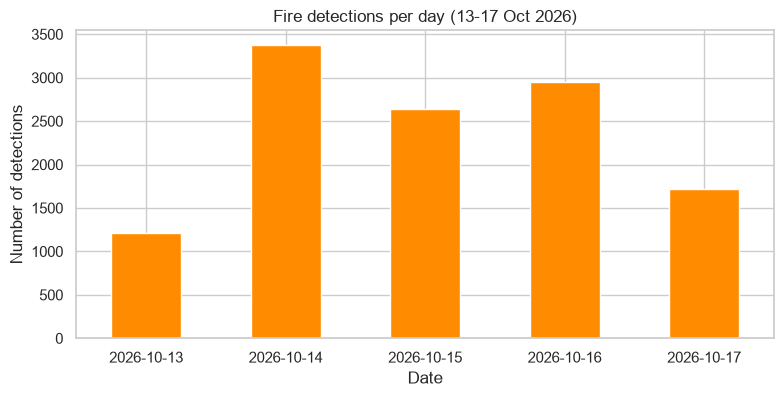

acq_date
2026-10-13    1207
2026-10-14    3377
2026-10-15    2641
2026-10-16    2949
2026-10-17    1720
dtype: int64


In [15]:
daily = fires_clean.groupby(fires_clean["acq_date"].dt.date).size()
plt.figure(figsize=(9, 4))
daily.plot(kind="bar", color="darkorange")
plt.title("Fire detections per day (13-17 Oct 2026)")
plt.xlabel("Date")
plt.ylabel("Number of detections")
plt.xticks(rotation=0)
plt.show()
print(daily)

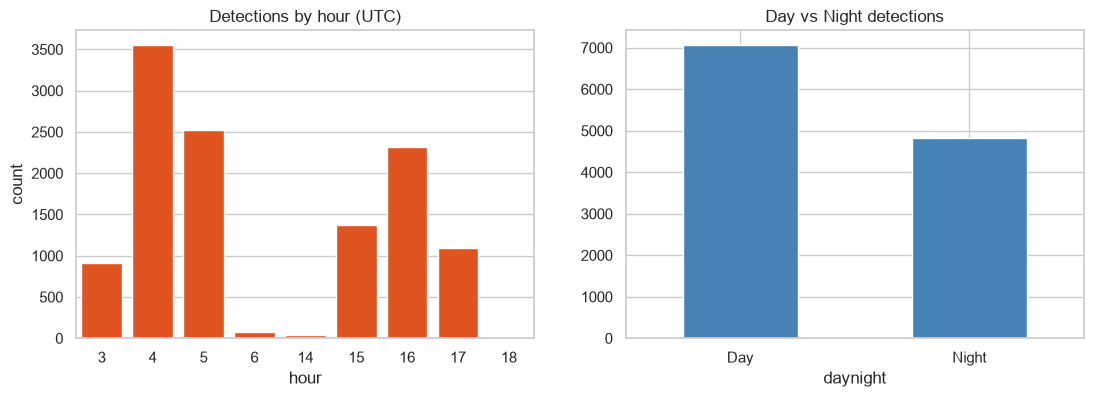

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x="hour", data=fires_clean, color="orangered", ax=ax[0])
ax[0].set_title("Detections by hour (UTC)")
fires_clean["daynight"].map({"D": "Day", "N": "Night"}).value_counts().plot(
    kind="bar", ax=ax[1], color="steelblue")
ax[1].set_title("Day vs Night detections")
ax[1].tick_params(axis="x", rotation=0)
plt.show()

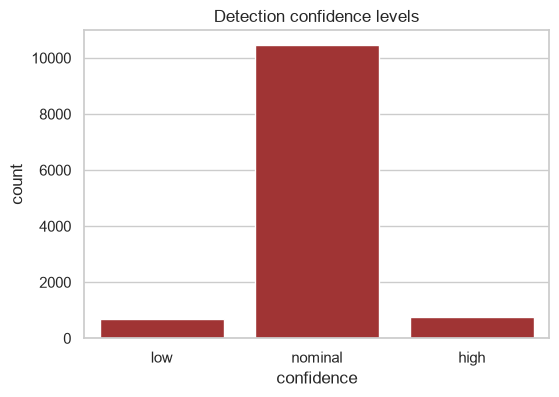

In [17]:
order = ["low", "nominal", "high"]
plt.figure(figsize=(6, 4))
sns.countplot(x="confidence", data=fires_clean, order=order, color="firebrick")
plt.title("Detection confidence levels")
plt.show()

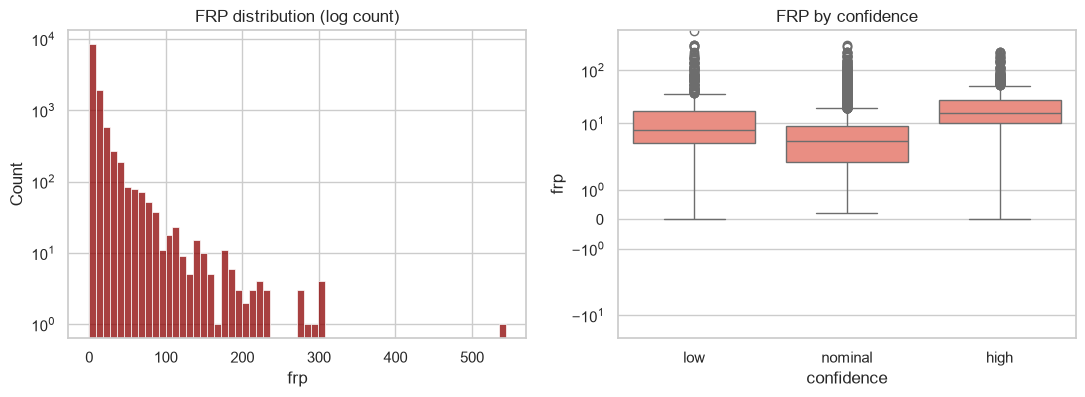

Median FRP: 5.27
99th percentile FRP: 102.60889999999992
Fires above 100 MW: 126


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(fires_clean["frp"], bins=60, color="darkred", ax=ax[0])
ax[0].set_yscale("log")
ax[0].set_title("FRP distribution (log count)")
sns.boxplot(x="confidence", y="frp", data=fires_clean, order=order, color="salmon", ax=ax[1])
ax[1].set_yscale("symlog")
ax[1].set_title("FRP by confidence")
plt.show()
print("Median FRP:", fires_clean["frp"].median())
print("99th percentile FRP:", fires_clean["frp"].quantile(0.99))
print("Fires above 100 MW:", (fires_clean["frp"] > 100).sum())

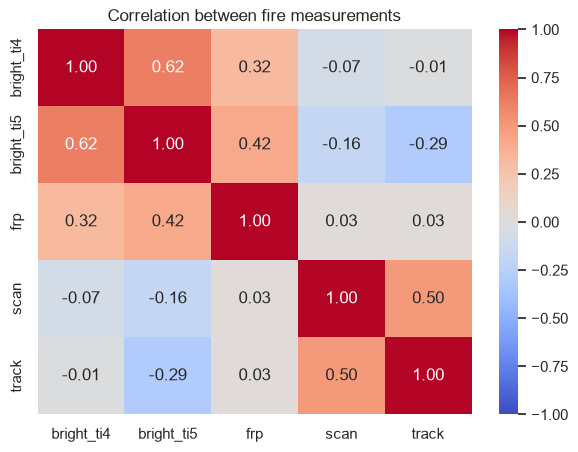

In [19]:
cols = ["bright_ti4", "bright_ti5", "frp", "scan", "track"]
plt.figure(figsize=(7, 5))
sns.heatmap(fires_clean[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation between fire measurements")
plt.show()

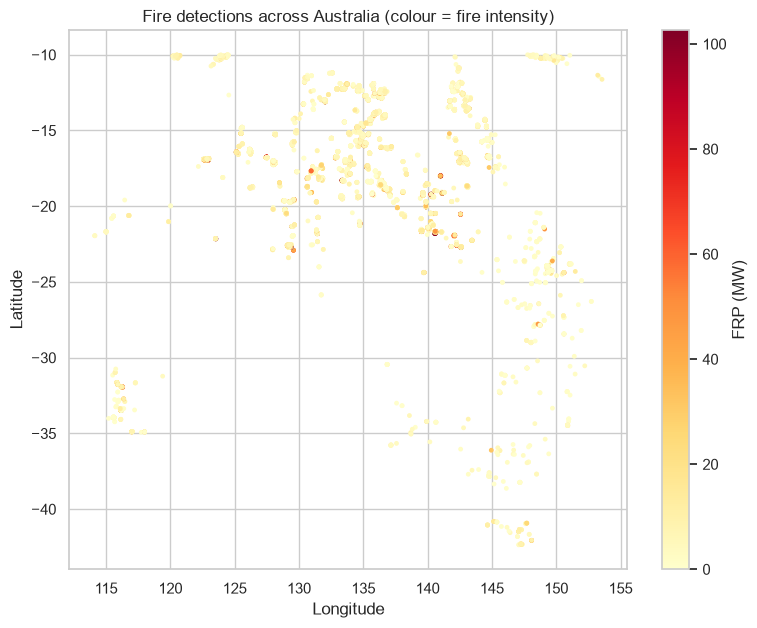

In [20]:
plt.figure(figsize=(9, 7))
sc = plt.scatter(fires_clean["longitude"], fires_clean["latitude"],
                 c=fires_clean["frp"], s=6, cmap="YlOrRd",
                 vmax=fires_clean["frp"].quantile(0.99))
plt.colorbar(sc, label="FRP (MW)")
plt.title("Fire detections across Australia (colour = fire intensity)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## Key Findings

### Data quality
- `forest_loss` (24 rows, 2001-2024) has no missing values or duplicate years.
- `fire_alerts` had 12,394 rows; **500 were exact duplicates** (same latitude, longitude, date, time). After removal, 11,894 rows remain, which matches the ETL log's processed count.
- `acq_date` was stored as text and was converted to datetime; confidence codes (l/n/h) were mapped to low/nominal/high.

### Forest loss (Australia, 2001-2024)
- Median annual loss is about 244,000 ha, but the mean (about 384,000 ha) is pulled up by two outlier years.
- 2019 (1.66M ha, +562% vs 2018) and 2020 (2.36M ha, the maximum) are clear outliers; loss returned to normal levels in 2021 and reached its minimum in 2022 (about 119,000 ha).
- The 2019-2020 spike coincides in time with Australia's 2019-20 bushfire season; this is a temporal coincidence and not proven by this dataset alone.

### Fire alerts (13-17 Oct 2026, VIIRS)
- Detections per day: 1,207 / 3,377 / 2,641 / 2,949 / 1,720. The first and last days are likely partial.
- Detections cluster in a few hours because they reflect satellite overpass times, not the true daily fire cycle.
- Around 7,000 detections occurred during the day vs about 4,800 at night.
- About 88% of detections have nominal confidence.
- Fire Radiative Power (FRP) is heavily right-skewed: median 5.27 MW, 99th percentile 102.6 MW, 126 fires above 100 MW.
- `bright_ti4` and `bright_ti5` are moderately correlated (0.62); FRP has weak correlation with brightness (0.32 / 0.42) and none with scan/track (0.03).
- Most detections are in northern Australia, with smaller clusters on the east coast and in the south-west.


## Conclusion and Limitations

- Annual forest loss is usually in the range of 120,000-430,000 ha, with an exceptional spike in 2019-2020.
- The fire dataset covers only 5 days, so it describes a short snapshot of fire activity, not a long-term trend.
- The two tables are at different time scales (yearly 2001-2024 vs 13-17 Oct 2026), so a year-by-year correlation between forest loss and fire counts is **not possible** with the current data. A multi-year FIRMS archive would be needed for that.
- `forest_loss` has a single region (AUS), so regional comparison is not possible.
- Recommended charts for the dashboard: annual forest loss line chart, daily fire counts, confidence split, and the fire intensity map.